# 선택한 구간만 사용하는 장기 이상 탐지

이전·다음 감시 배치의 상태를 사용하지 않고, **현재 1·4·8·12·24시간만** 판정한 최신 연구 결과다. 정상 참고 자료는 과거 28일이다.

4·8·12·24시간은 네 지표 중앙값 65% 이상·오탐률 6% 이하를 충족했다. **1시간은 미달이므로 전체 목표는 아직 달성하지 못했다.** 기능 구현·검증 통과와 성능 목표 달성을 구분한다.

## 1. 무엇을 평가했는가

- 시나리오 6개: 지속 지연, 점진적 악화, 지속 폭주, 지속 입력 감소, 일일 패턴 변화, 변동성 증가. 어려운 시나리오를 제외하지 않았다.
- 입력은 시간당 Process 실행 수와 소요시간의 로그 집계다. 1시간 입력은 1행이다.
- 각 배치 안에서만 평균·중앙값·변동성을 계산한다. 같은 길이의 정상 구간 분포와 비교한다.
- 배치당 점수 하나를 관측된 각 시간에 제공한다. 장애 시작 시각을 정확히 추정한다는 뜻은 아니다.
- 원래 시간별 정답을 유지했다. 배치 정답 확장이나 point adjustment는 없다.
- 기존에 공개한 반합성 평가셋을 재사용한 비교다. 새로운 독립 블라인드 평가나 실제 운영 성능이 아니다.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
cwd = Path.cwd()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / 'data/evaluation_long_term/manifest.json').exists())
if str(ROOT / 'code') not in sys.path:
    sys.path.insert(0, str(ROOT / 'code'))
from long_term_anomaly.common import read_json
from long_term_anomaly.strict_intervals.report import table, scenario_table
OUT = ROOT / 'reports/long_term_anomaly/strict_intervals'
results = read_json(OUT / 'results.json')
pd.options.display.float_format = '{:.2f}'.format
display(Markdown(f"평가 대상: **각 길이에서 동일한 {results['results']['1']['pooled']['assessed_hours']:,}개 관측 시간**. 수집 중단은 정상 0으로 세지 않았다."))

평가 대상: **각 길이에서 동일한 192,178개 관측 시간**. 수집 중단은 정상 0으로 세지 않았다.

## 2. 길이별 성능 핵심

표와 그림의 Accuracy·Precision·Recall·F1은 **6개 시나리오에서 계산한 지표의 중앙값**이다. 모든 시나리오가 각각 이 수치라는 뜻은 아니다.

- Accuracy: 전체 판단 중 맞힌 비율. 정상 비중이 크면 놓치는 이상이 있어도 높을 수 있다.
- Precision: 경보 중 실제 이상인 비율.
- Recall: 실제 이상 중 탐지한 비율. 높을수록 덜 놓친다.
- F1: Precision과 Recall을 함께 보는 조화평균.

1시간의 Accuracy만 보고 충분하다고 판단하면 안 된다. 1시간의 Recall·F1·Precision은 목표에 못 미친다.

,분석 구간,Accuracy,Precision,Recall,F1,전체 오탐률,시나리오 최대 오탐률
0,1시간,87.62,63.37,48.08,54.68,5.04,5.28
1,4시간,90.94,75.93,69.67,72.74,3.72,4.69
2,8시간,92.29,80.88,75.95,75.87,3.71,5.37
3,12시간,92.81,78.38,76.53,77.39,4.14,5.17
4,24시간,93.44,78.23,80.90,79.86,3.89,5.64


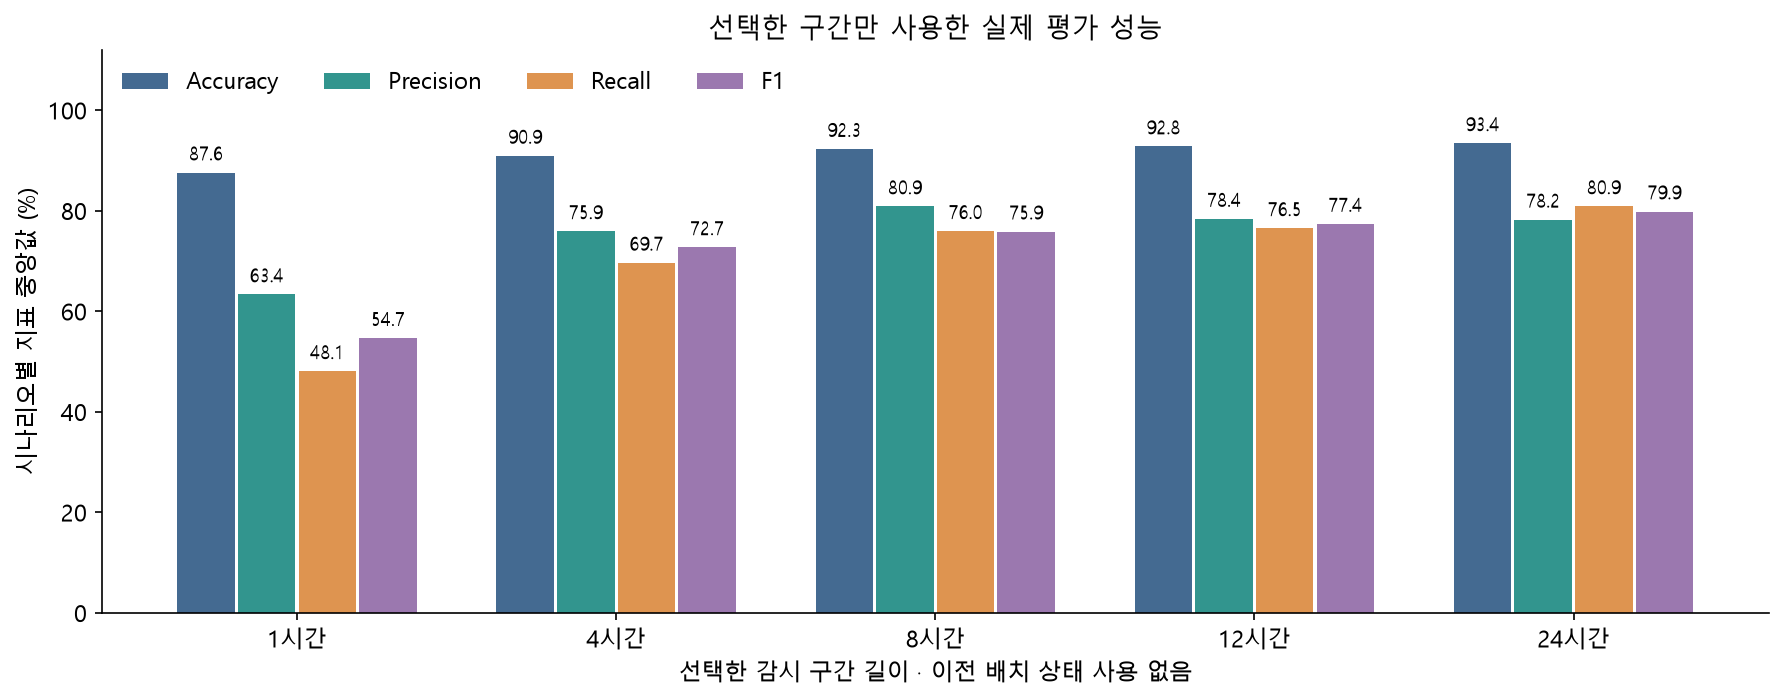

,분석 구간,네 지표 중앙값 ≥65% 및 오탐률 ≤6%
0,1시간,False
1,4시간,True
2,8시간,True
3,12시간,True
4,24시간,True


In [2]:
display(table('median'))
display(Image(filename=str(OUT / 'figures/metrics_median.png')))
status = pd.DataFrame([{'분석 구간': f'{h}시간', '네 지표 중앙값 ≥65% 및 오탐률 ≤6%': r['target_met']} for h, r in results['results'].items()])
display(status)

## 3. 오탐률은 실제로 얼마인가

오탐률은 **정상 시간 중 경보를 낸 비율**이다. Precision과 분모가 다르다. 전체 정상 시간을 합친 오탐률과 시나리오별 오탐률 중 최댓값을 함께 본다.

모든 길이에서 최대 시나리오 오탐률은 6% 이내다. 기존 모델과 똑같은 오탐률을 유지했다는 뜻은 아니며, 허용한 6% 조건 안에서 Recall을 높인 결과다. 그림에는 목표선을 추가하지 않고 실제 값만 표시했다.

,분석 구간,전체 오탐률,시나리오 최대 오탐률
0,1시간,5.04,5.28
1,4시간,3.72,4.69
2,8시간,3.71,5.37
3,12시간,4.14,5.17
4,24시간,3.89,5.64


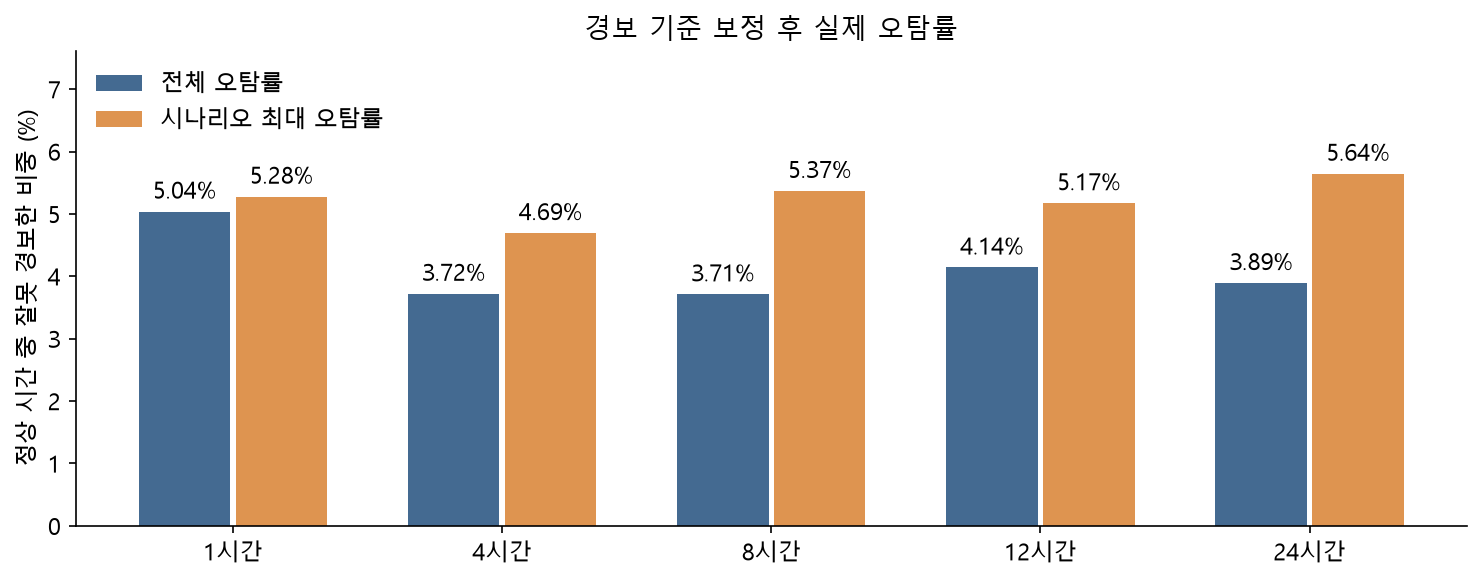

In [3]:
display(table()[['분석 구간', '전체 오탐률', '시나리오 최대 오탐률']])
display(Image(filename=str(OUT / 'figures/false_positive_rates.png')))

## 4. 모델을 어떻게 바꿨는가

정상 데이터는 위·아래 꼬리의 길이가 같지 않았다. 편차의 절댓값 하나 대신 상위 편차·하위 편차·밀도 점수를 따로 만들었다.

예를 들어 4시간 모드는 **현재 4개의 시간당 실행 수와 소요시간**에서 평균·중앙값·표준편차를 계산한다. 이를 정상 28일 안에서 얻은 여러 4시간 구간의 분포와 비교한다. 4시간 이전 감시 자료를 붙여서 계산하지 않는다.

피처는 `통계 3종 × 채널 2종 × 상위·하위·밀도 3종 = 18개`다. 요청 수와 소요시간의 가중치, 밀도 방법, 경보 기준을 길이별로 선택했다. 아래 가중치는 피처 점수의 배율이며 중요도 백분율이 아니다.

정상 분포는 정상 참고 자료에서만 학습한다. **개발셋 정답은 가중치·설정 선택에 사용했고, 테스트 정답으로 선택하지 않았다.** 최종 모델은 시간대 정상분포 + 구간 통계·밀도 모델이며, 누적 감시 상태나 PELT 분할을 사용하지 않는다. 처리 건수는 입력 호환용으로 유지하지만 현재 점수에는 사용하지 않는다.

In [4]:
calibration = read_json(OUT / 'calibration.json')
display(pd.DataFrame([{'분석 구간': f'{h}시간', '밀도 방식/대역폭': r['settings']['density'], 'threshold': r['settings']['threshold'], '개발 정상 오탐 예산': r['settings']['cap']} for h, r in calibration['models'].items()]))
names = calibration['model_record']['feature_names']
weights = pd.DataFrame({f'{h}시간': r['settings']['weights'] for h, r in calibration['models'].items()}, index=names)
display(weights)

,분석 구간,밀도 방식/대역폭,threshold,개발 정상 오탐 예산
0,1시간,0.25,4.56,0.06
1,4시간,knn,2.76,0.04
2,8시간,0.10,3.50,0.04
3,12시간,0.10,3.68,0.04
4,24시간,0.10,4.36,0.04


,1시간,4시간,8시간,12시간,24시간
mean_upper:requests,1.00,1.00,1.00,1.00,1.00
mean_lower:requests,0.06,0.25,1.09,0.98,1.97
mean_density:requests,0.27,0.00,0.22,0.04,0.06
mean_upper:duration,2.83,2.00,1.06,0.57,2.72
mean_lower:duration,2.68,0.50,0.49,0.29,0.77
mean_density:duration,0.49,0.00,0.32,0.87,0.26
median_upper:requests,1.28,1.00,1.72,1.48,0.13
median_lower:requests,0.07,0.25,1.87,1.45,0.26
median_density:requests,0.35,0.00,0.37,0.07,0.01
median_upper:duration,3.63,2.00,1.81,0.84,0.36


## 5. 어떤 시나리오를 잘 잡고, 무엇을 놓쳤는가

아래 두 그림을 함께 본다. Recall은 놓친 이상을, F1은 탐지율과 경보 정확도의 균형을 보여준다.

지속 지연·폭주처럼 수준이 바뀌는 상황은 구간의 평균·중앙값이 유용하다. 변동성 증가는 표준편차와 밀도 점수가 보완한다. 하루 패턴의 일부나 지연이 아직 약한 구간은 짧은 입력만으로 구분하기 어려울 수 있다. **특정 시나리오의 결과를 숨기지 않고 여섯 개를 모두 표시했다.** 특히 4시간의 지속 입력 감소와 24시간의 일일 패턴 변화는 탐지율이 매우 낮다. 중앙값을 통과했다고 해서 이 시나리오까지 잘 탐지한 것은 아니며, 별도 개선 대상으로 남는다.

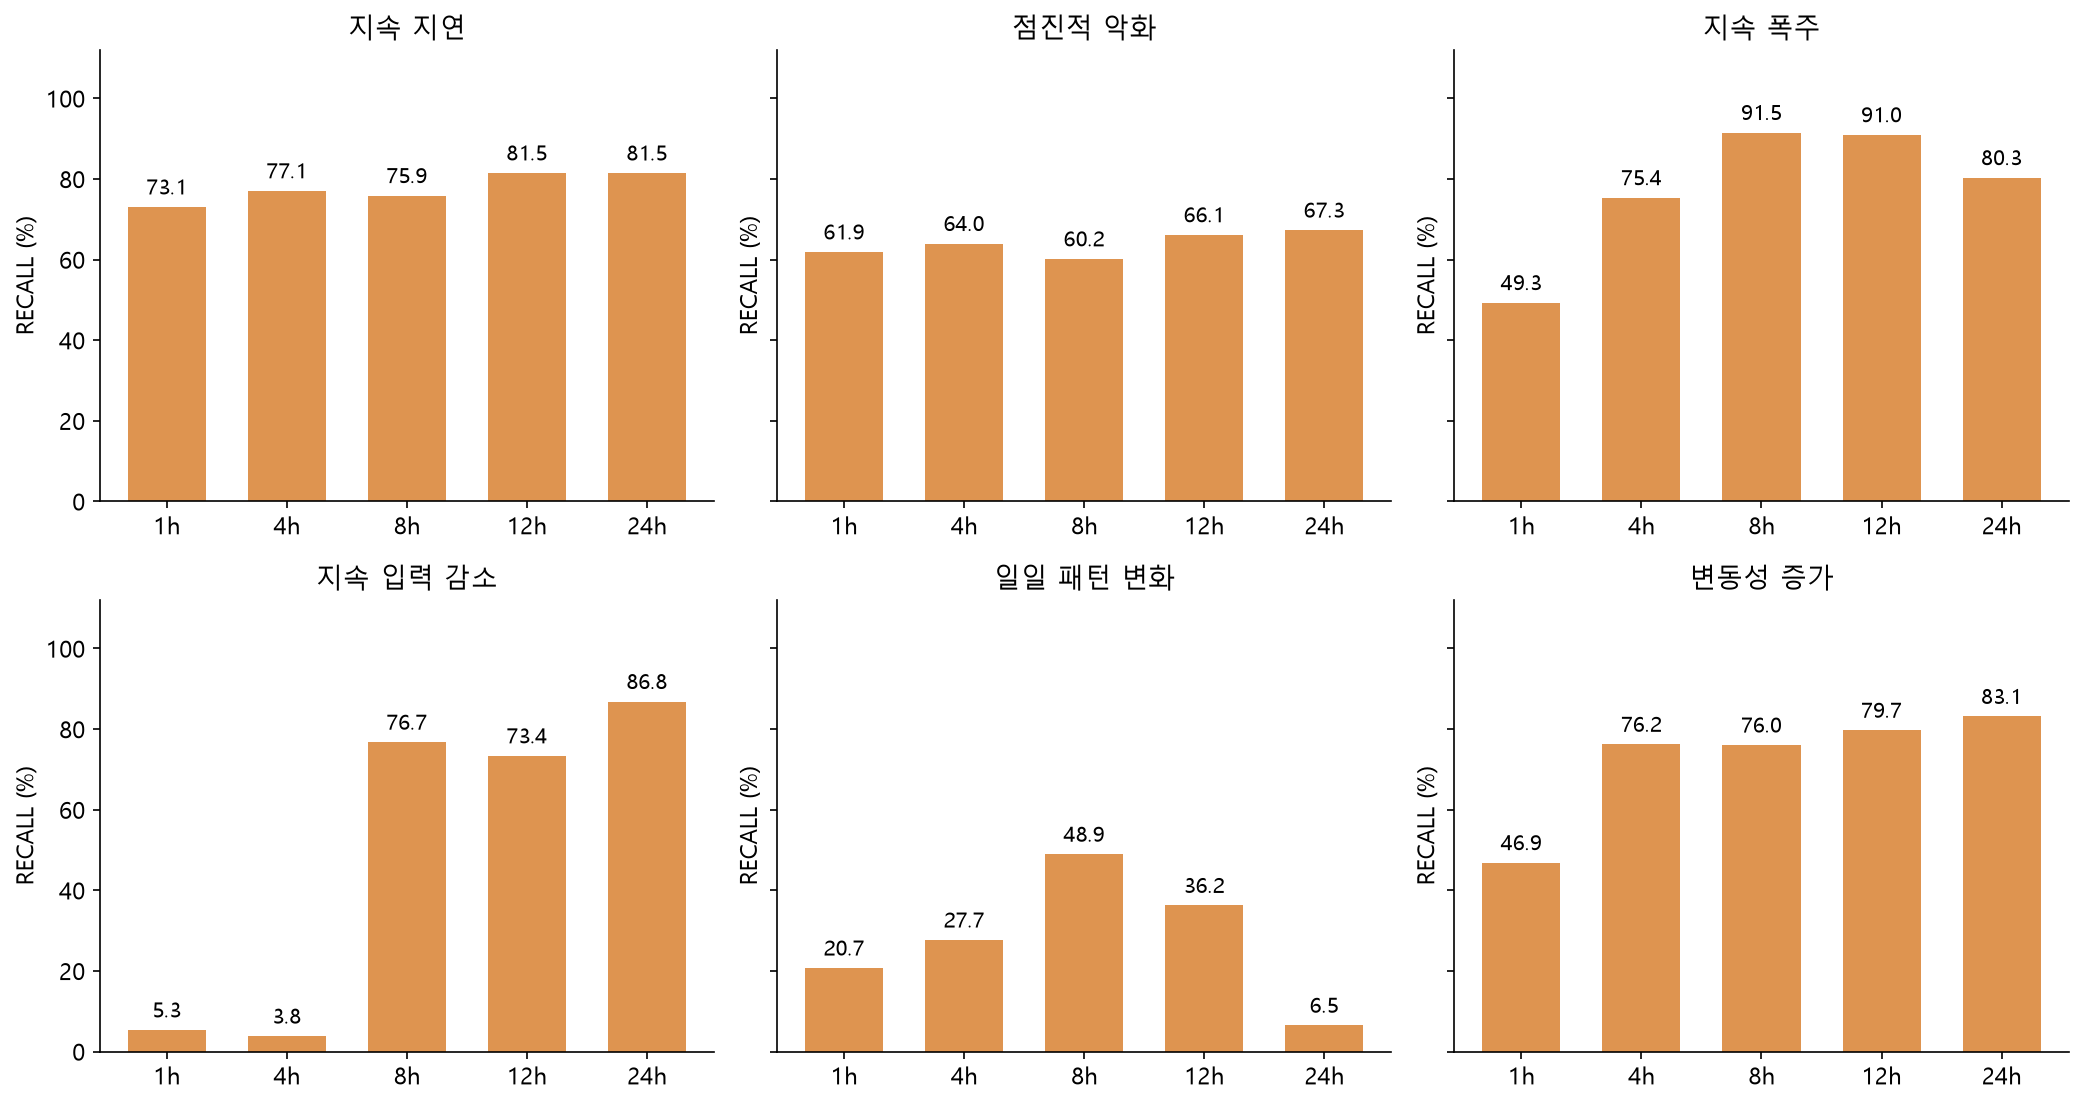

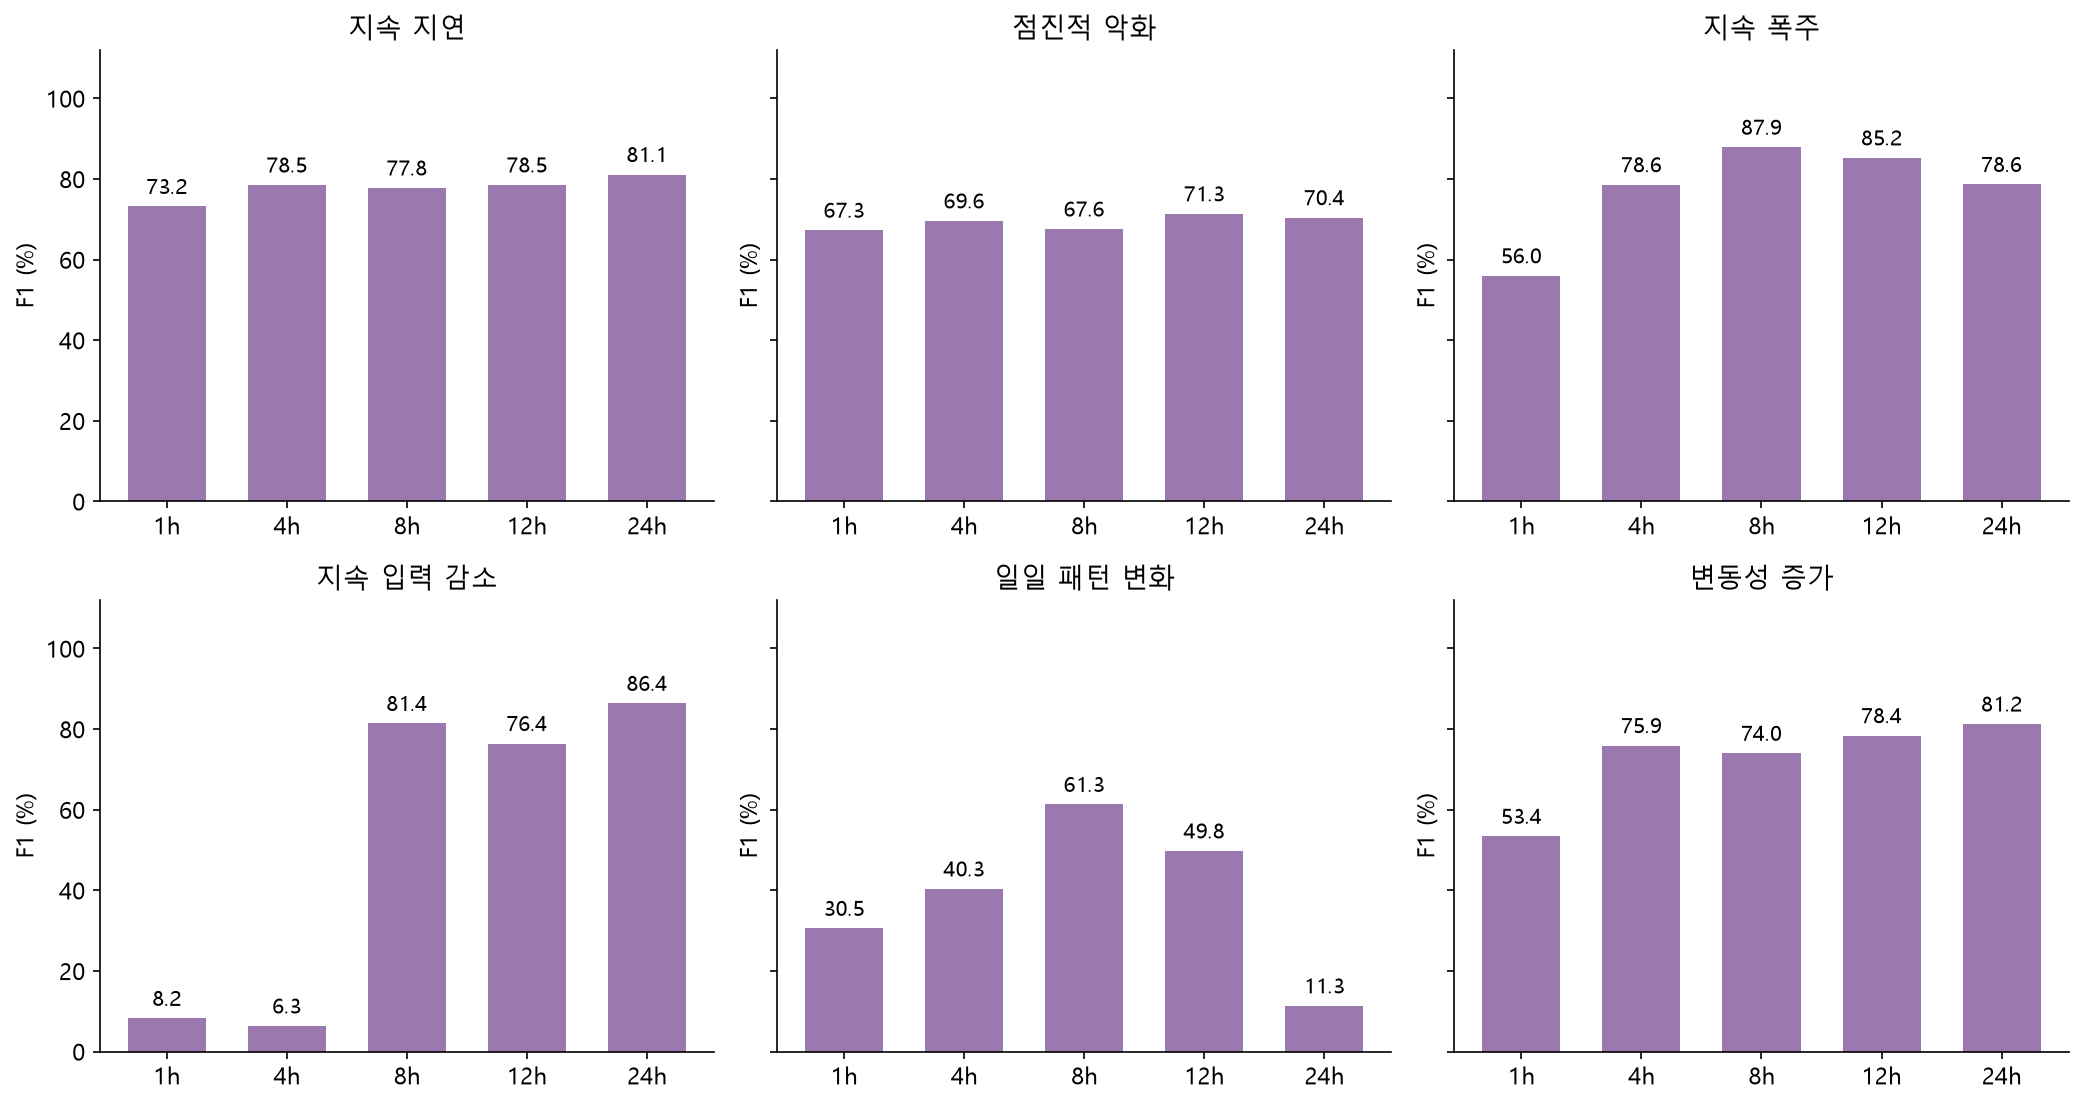

In [5]:
display(Image(filename=str(OUT / 'figures/scenario_recall.png')))
display(Image(filename=str(OUT / 'figures/scenario_f1.png')))

## 6. 1시간 모드의 미달을 따로 확인

1시간에는 실행 수와 소요시간이 각각 한 점뿐이다. 정상 시간대 분포와의 차이는 볼 수 있지만, 장기간 반복·지속·점진 변화 자체를 현재 입력에서 관측할 수는 없다. 예를 들어 하루 주기가 변했더라도 특정 한 시간의 값은 정상 범위일 수 있다.

비대칭 꼬리, kNN·KDE, 결합 밀도, 정상 자료 가상 변형 자기지도 후보를 개발셋에서 비교했다. 자기지도 후보는 더 좋지 않아 저장 모델에서 제외했다. **아래 미달이 모든 가능한 1시간 모델의 수학적 불가능성을 증명하는 것은 아니다.** 이전 감시 로그를 몰래 사용하거나 난도를 바꿔 달성으로 처리하지 않았다.

In [6]:
display(scenario_table(1))
display(Markdown(f"1시간 중앙값: Precision **{100*results['results']['1']['median']['precision']:.2f}%**, Recall **{100*results['results']['1']['median']['recall']:.2f}%**, F1 **{100*results['results']['1']['median']['f1']:.2f}%**. 전체 목표 달성 여부: **{results['goal_met_all_lengths']}**."))

,시나리오,Accuracy,Precision,Recall,F1,오탐률
0,일일 패턴 변화,76.48,58.17,20.71,30.55,4.96
1,점진적 악화,88.51,73.69,61.89,67.28,5.21
2,지속 지연,91.14,73.29,73.06,73.17,5.28
3,지속 입력 감소,81.51,17.64,5.35,8.21,4.57
4,지속 폭주,87.84,64.69,49.31,55.96,5.00
5,변동성 증가,87.41,62.05,46.85,53.39,5.21


1시간 중앙값: Precision **63.37%**, Recall **48.08%**, F1 **54.68%**. 전체 목표 달성 여부: **False**.

## 7. 데이터 점수 분포와 실제 경보 기준

점수를 실제 threshold로 나눈 값이다. **1을 초과하면 경보**다. 파란색은 원래 정상 정답, 주황색은 원래 이상 정답이다. 각 집단을 따로 100%로 정규화했으므로 전체 정상·이상 개수 차이에 가려지지 않는다.

두 분포가 겹치는 부분에서는 오탐·미탐이 함께 생길 수 있다. 그림 범위보다 큰 값도 버리지 않고 마지막 막대에 모두 포함했다. 실제 경보 판단은 원래 점수로 했으며, 그리기 위한 상단 묶음은 지표 계산과 무관하다.

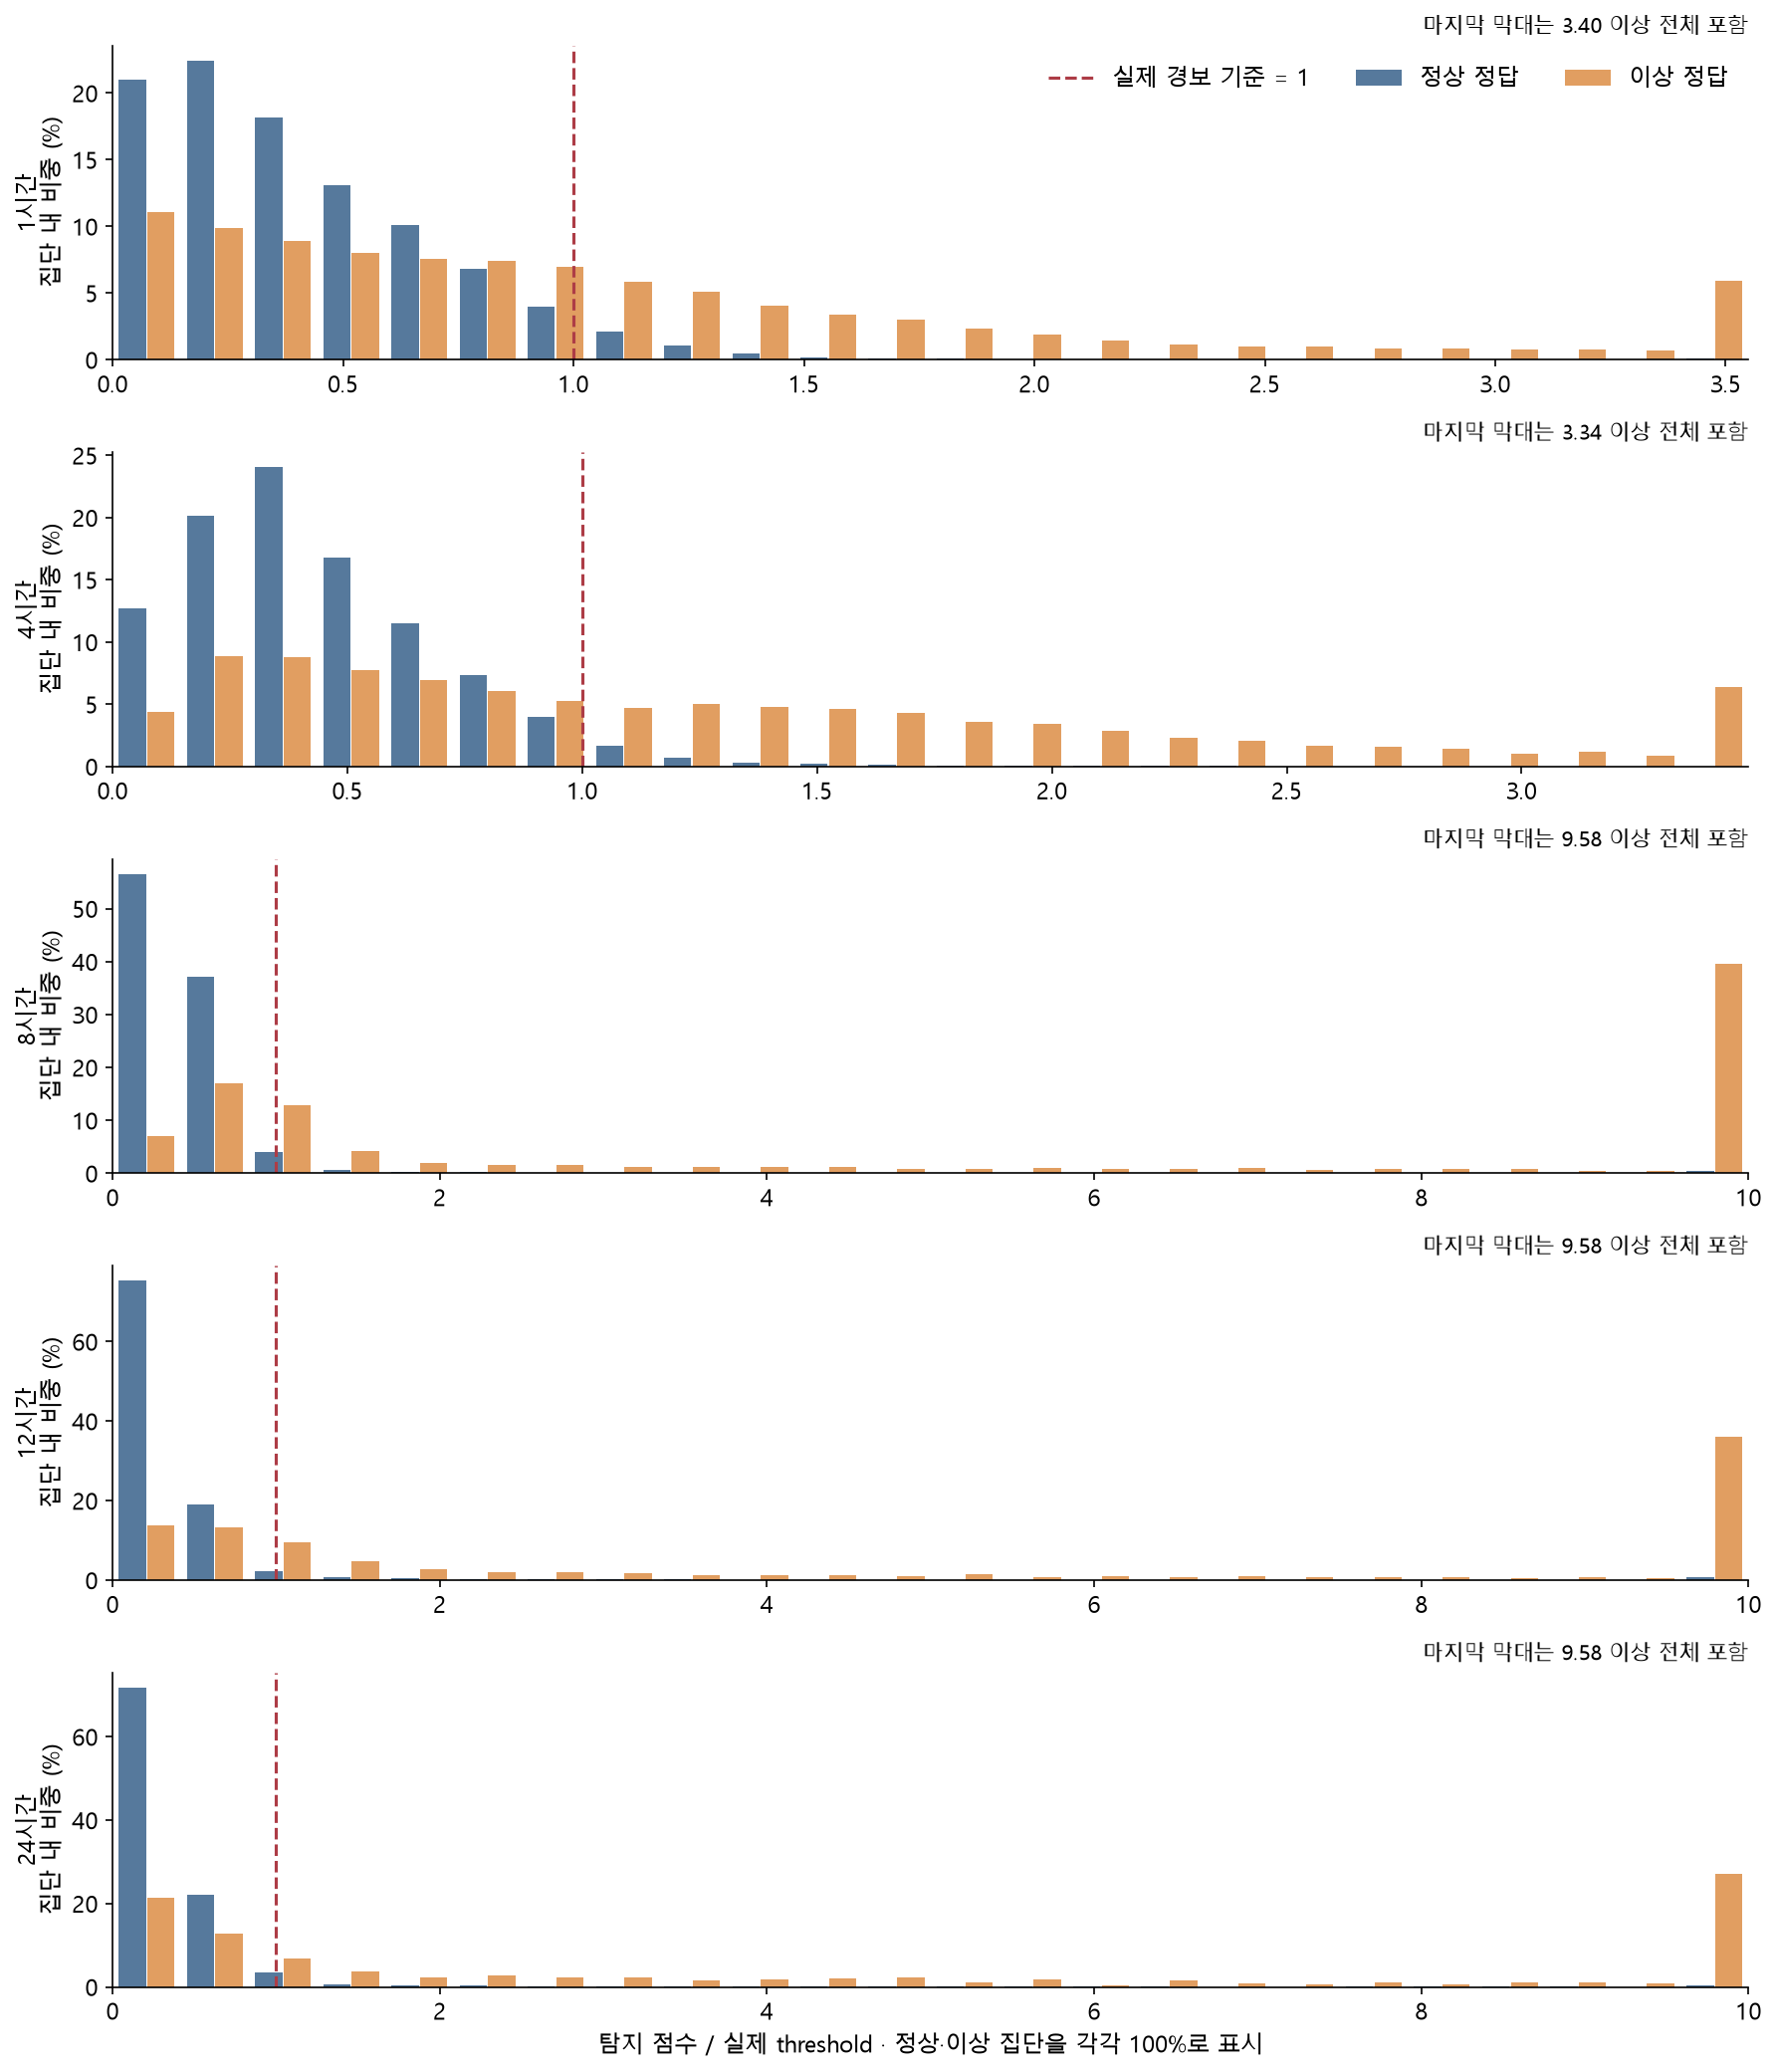

In [7]:
display(Image(filename=str(OUT / 'figures/score_distributions.png')))

## 8. 점진적 악화 사례는 어떻게 읽는가

점수로 좋은 사례를 고르지 않고, 파일 순서상 첫 점진적 악화 주입 사례를 표시했다. 주황 배경은 보고서에만 사용하는 원래 이상 정답이다. 모델 입력이 아니다.

점수/기준이 1보다 크면 해당 배치에서 경보한다. 배치 안에서는 점수가 같으며, 그 배치가 끝난 뒤 결과가 제공된다. 24시간 점수가 하루 동안 일정하다고 해서 하루 시작 순간부터 결과를 알고 있었다는 뜻은 아니다. 다음 배치의 값으로 앞선 배치를 수정하지도 않는다.

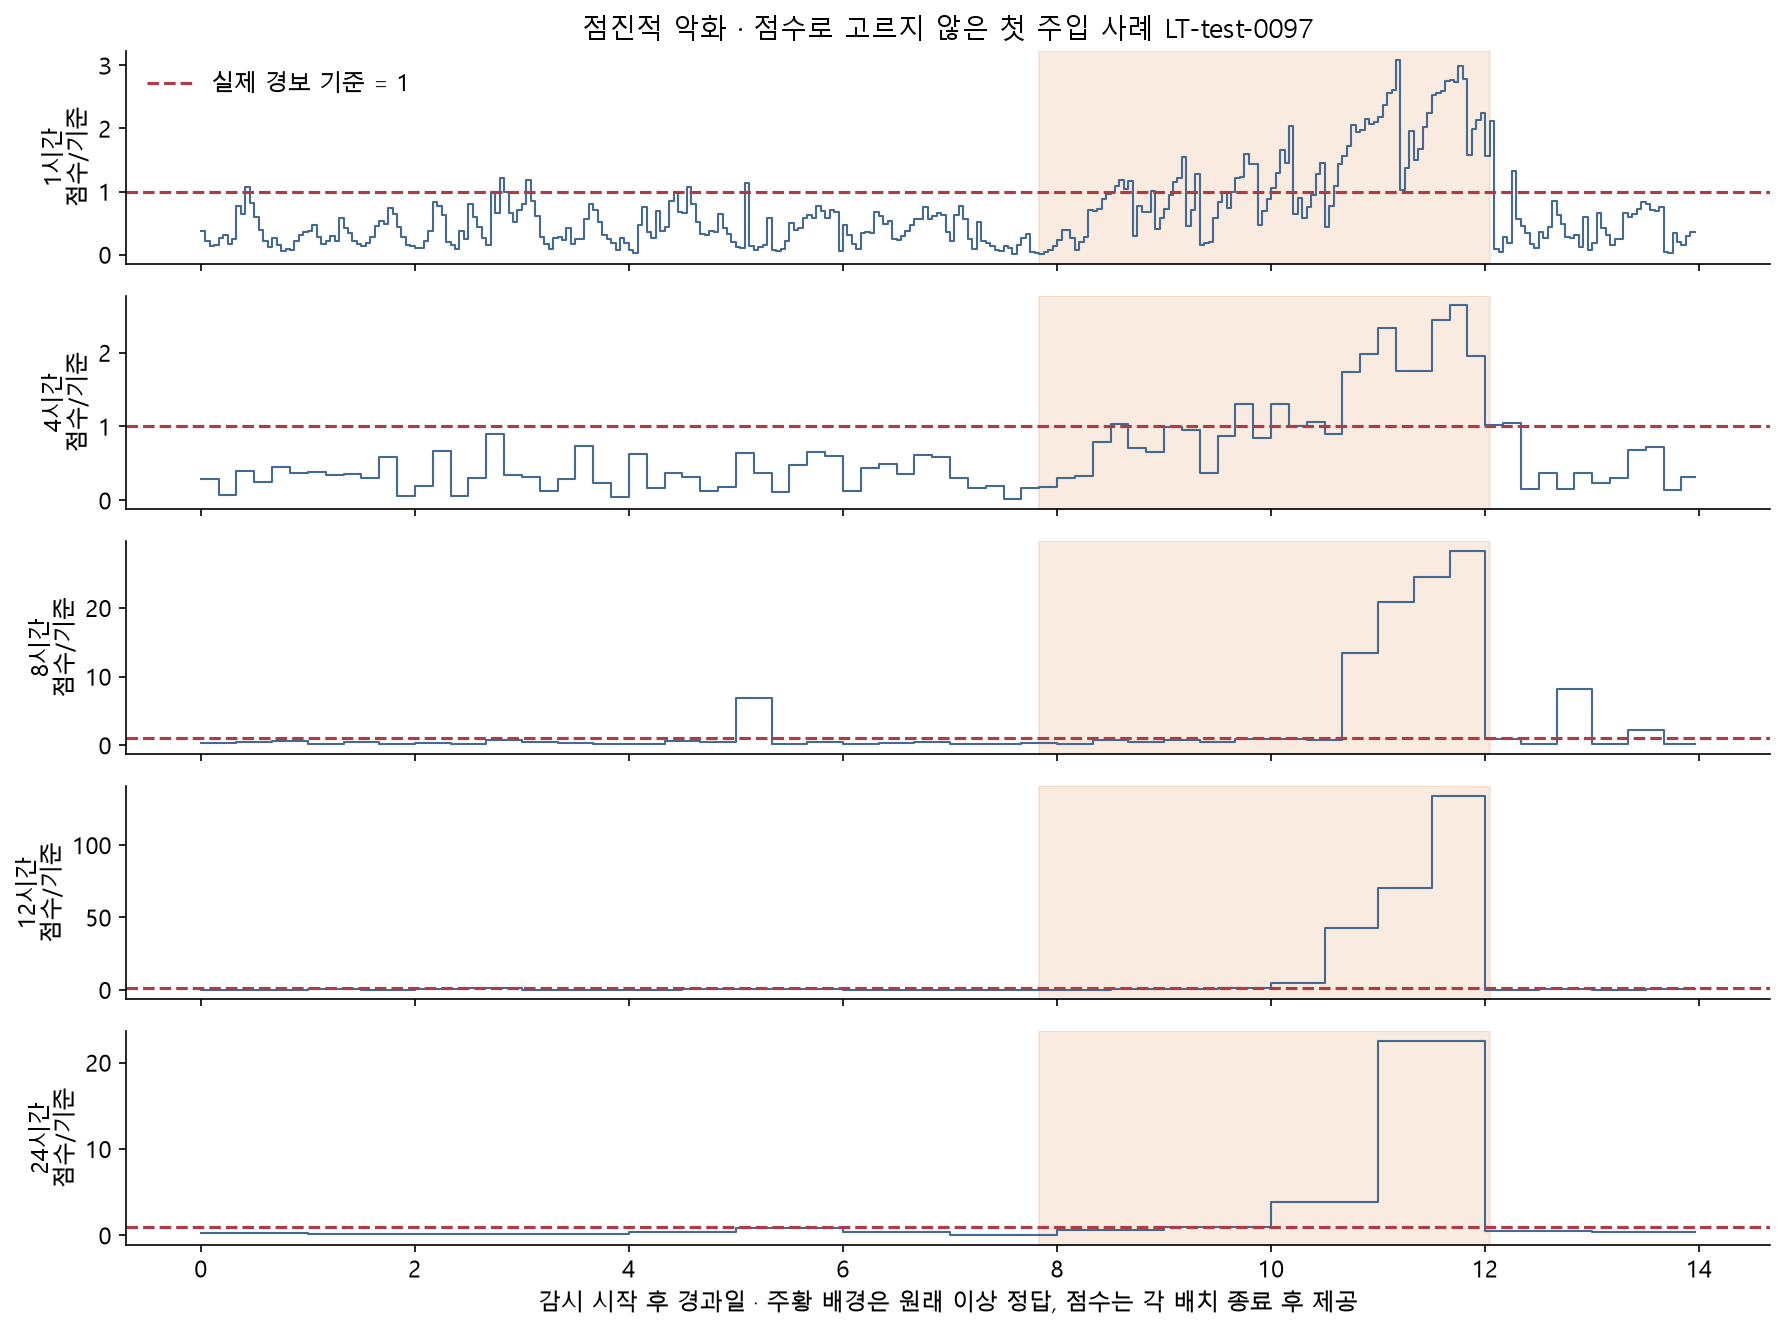

,analysis_hours,scenario,result,reason,hour_count
289,24,gradual_degradation,정답 이상 탐지,mean_density:duration,3761
293,24,gradual_degradation,정상 오탐,mean_density:duration,680
295,24,gradual_degradation,정상 오탐,mean_upper:duration,512
290,24,gradual_degradation,정답 이상 탐지,mean_upper:duration,251
296,24,gradual_degradation,정상 오탐,std_density:duration,178
294,24,gradual_degradation,정상 오탐,mean_density:requests,96
292,24,gradual_degradation,정답 이상 탐지,std_density:duration,86
291,24,gradual_degradation,정답 이상 탐지,median_density:duration,24


In [8]:
display(Image(filename=str(OUT / 'figures/timeline_gradual_degradation.png')))
reasons = pd.read_csv(OUT / 'detection_reasons.csv')
display(reasons[(reasons.analysis_hours == 24) & (reasons.scenario == 'gradual_degradation')].sort_values('hour_count', ascending=False).head(10))

## 9. 중앙값과 전체 시간 통합 지표는 다르다

앞의 목표는 시나리오 6개 지표의 중앙값이다. 아래는 모든 시간의 TP·FP·TN·FN을 합쳐 다시 계산한 값이다.

따라서 중앙값 목표를 통과했다고 해서 아래 통합 Recall·F1도 65%를 넘는다는 뜻은 아니다. 시나리오별 난도·이상 시간 수가 다르고 중앙값은 각 시나리오를 동일하게 한 표본으로 보기 때문이다. 운영 적용에서는 두 결과를 함께 확인해야 한다.

,분석 구간,Accuracy,Precision,Recall,F1,전체 오탐률,시나리오 최대 오탐률
0,1시간,85.48,64.36,41.86,50.73,5.04,5.28
1,4시간,88.42,75.33,52.27,61.72,3.72,4.69
2,8시간,91.46,80.22,69.23,74.32,3.71,5.37
3,12시간,90.92,78.15,68.17,72.82,4.14,5.17
4,24시간,90.08,77.68,62.33,69.16,3.89,5.64


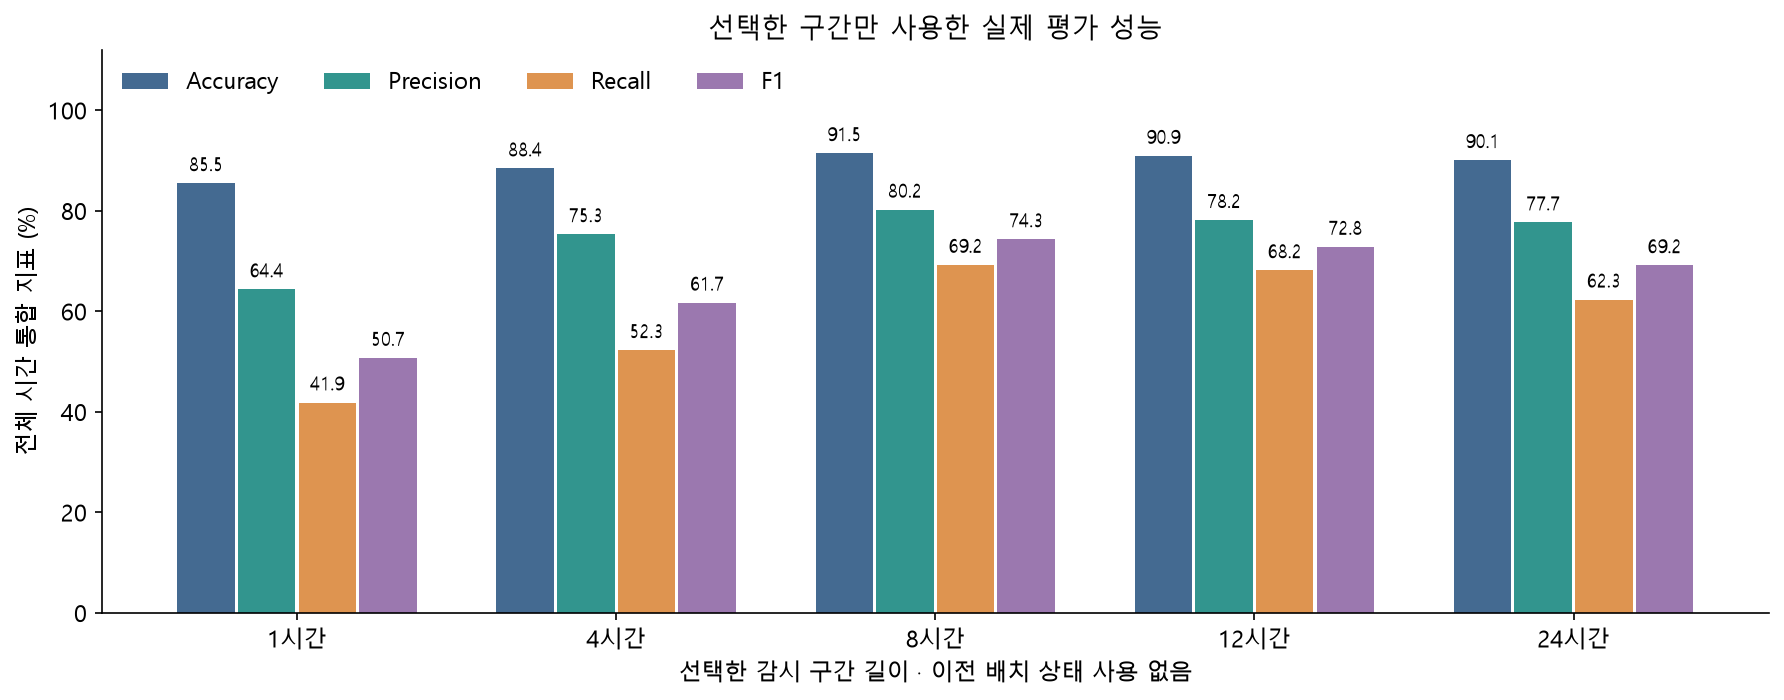

In [9]:
display(table('pooled'))
display(Image(filename=str(OUT / 'figures/metrics_pooled.png')))

## 10. 검증과 사용법

원본 기간 데이터·기존 모델·기존 노트북·벤치마크의 해시를 확인했고, 저장 점수에서 전체 지표를 독립 재계산했다. 6개 시나리오의 대표 사례 × 5개 길이, 총 30개 전체 API 재생 결과도 저장 예측과 비교했다. 단위 테스트에는 이전·다음 감시 배치 변경 불변성, 결측, 시각 정렬, 저장·복원 검사가 포함된다.

```python
from long_term_anomaly.strict_intervals import load_bank
bank = load_bank('reports/long_term_anomaly/strict_intervals/models.joblib')
reference = bank.prepare_reference(normal_history_28days)
result = bank.predict_batch(reference, current_4hours, analysis_hours=4)
```

입력 계약·주의사항은 같은 폴더의 README.md에 있다. 정상 참고 자료는 검토된 정상 구간이어야 하며, 감시 자료를 자동으로 정상 참고 자료에 추가하지 않는다.

근거 원리: [NIST 이상값 탐지의 분포 가정 주의](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm), [SciPy 밀도 추정·대역폭](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.gaussian_kde.html). 실제 성능 근거는 수정하지 않은 로컬 벤치마크와 저장된 예측이다.

In [10]:
verification = read_json(OUT / 'validation.json')
display(pd.DataFrame([{'검증 항목': k, '확인 결과': v} for k, v in verification['checks'].items()]))
display(pd.DataFrame([{'분석 구간': f'{h}시간', '성능 목표 충족': v} for h, v in verification['goal_per_length'].items()]))
display(Markdown(f"파일·추론·지표 검증: **{verification['integrity_passed']}**. 전체 성능 목표 달성: **{verification['goal_met_all_lengths']}**. 이 둘은 별개다."))

,검증 항목,확인 결과
0,all_original_models_notebooks_reports_and_benc...,True
1,all_three_raw_periods_unchanged,True
2,model_code_selection_and_predictions_hashes_match,True
3,no_independent_blind_test_claim,True
4,same_all_original_observed_hours_for_every_length,True
5,all_30_scenarios_and_five_pooled_metrics_recom...,True
6,all_medians_and_65_percent_goal_flags_independ...,True
7,thirty_full_dataframe_API_replays_match_frozen...,True
8,no_monitoring_state_in_model_contract,True


,분석 구간,성능 목표 충족
0,1시간,False
1,4시간,True
2,8시간,True
3,12시간,True
4,24시간,True


파일·추론·지표 검증: **True**. 전체 성능 목표 달성: **False**. 이 둘은 별개다.